# Objetivo del análisis

**Pregunta de negocio:** ¿Qué categorías, subcategorías/productos y regiones generan o destruyen rentabilidad, y en qué segmentos de descuento conviene investigar las pérdidas?

Para responderla, compararemos ventas y ganancias agregadas por categoría, subcategoría, producto, región y estado. Revisaremos las ganancias y los márgenes según los valores de descuento observados, buscando patrones que indiquen dónde profundizar.

- El margen agregado se calculará como ganancia total dividida entre ventas totales; no se promediarán los márgenes por fila.
- Empezaremos por los valores de descuento presentes en el dataset, sin agruparlos en intervalos arbitrarios.
- El análisis identifica asociaciones descriptivas, no prueba que los descuentos causen pérdidas.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

In [2]:
data_candidates = [
    Path("data/raw/Sample - Superstore.csv"),
    Path("../data/raw/Sample - Superstore.csv"),
]
data_path = next((path for path in data_candidates if path.is_file()), None)
if data_path is None:
    expected_paths = ", ".join(str(path) for path in data_candidates)
    raise FileNotFoundError(
        f"No se encontró el CSV desde {Path.cwd()}. "
        f"Rutas probadas: {expected_paths}"
    )

df = pd.read_csv(data_path, encoding="latin1")

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [4]:
missing_values = df.isna().sum()
print("Valores faltantes por columna:")
display(missing_values.to_frame(name="missing_values"))
print(f"Filas exactamente duplicadas: {df.duplicated().sum()}")

Valores faltantes por columna:


,missing_values
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


Filas exactamente duplicadas: 0


In [5]:
df['Order Date'] = pd.to_datetime(df['Order Date'], format="%m/%d/%Y")
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format="%m/%d/%Y")

In [6]:
df['year'] = df['Order Date'].dt.year
df['month'] = df['Order Date'].dt.month
df['day_of_week'] = df['Order Date'].dt.day_name()

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,year,month,day_of_week
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,11,Tuesday
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,11,Tuesday
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,6,Sunday
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,10,Sunday
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,10,Sunday


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   str           
 2   Order Date     9994 non-null   datetime64[us]
 3   Ship Date      9994 non-null   datetime64[us]
 4   Ship Mode      9994 non-null   str           
 5   Customer ID    9994 non-null   str           
 6   Customer Name  9994 non-null   str           
 7   Segment        9994 non-null   str           
 8   Country        9994 non-null   str           
 9   City           9994 non-null   str           
 10  State          9994 non-null   str           
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   str           
 13  Product ID     9994 non-null   str           
 14  Category       9994 non-null   str           
 15  Sub-Category   9994 non-null   s

In [8]:
df.describe()

,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit,year,month
count,9994.000000,9994,9994,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,2016-04-30 00:07:12.259355,2016-05-03 23:06:58.571142,55190.379428,229.858001,3.789574,0.156203,28.656896,2015.722233,7.809686
min,1.000000,2014-01-03 00:00:00,2014-01-07 00:00:00,1040.000000,0.444000,1.000000,0.000000,-6599.978000,2014.000000,1.000000
25%,2499.250000,2015-05-23 00:00:00,2015-05-27 00:00:00,23223.000000,17.280000,2.000000,0.000000,1.728750,2015.000000,5.000000
50%,4997.500000,2016-06-26 00:00:00,2016-06-29 00:00:00,56430.500000,54.490000,3.000000,0.200000,8.666500,2016.000000,9.000000
75%,7495.750000,2017-05-14 00:00:00,2017-05-18 00:00:00,90008.000000,209.940000,5.000000,0.200000,29.364000,2017.000000,11.000000
max,9994.000000,2017-12-30 00:00:00,2018-01-05 00:00:00,99301.000000,22638.480000,14.000000,0.800000,8399.976000,2017.000000,12.000000
std,2885.163629,NaN,NaN,32063.693350,623.245101,2.225110,0.206452,234.260108,1.123555,3.284654


In [9]:
df.shape

(9994, 24)

In [10]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,year,month,day_of_week
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,11,Tuesday
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,11,Tuesday
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,6,Sunday
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,10,Sunday
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,10,Sunday


## Análisis de ventas por categoría y subcategoría

In [11]:
# ¿Cuál categoria genera más ingresos?
sales_category = (df.groupby('Category')['Sales'].sum().sort_values(ascending=False))
print (sales_category)

Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64


In [12]:
# Ver ganancias por categoría
profit_category = df.groupby('Category')['Profit'].sum().sort_values(ascending=False)
print(profit_category)

Category
Technology         145454.9481
Office Supplies    122490.8008
Furniture           18451.2728
Name: Profit, dtype: float64


In [13]:
# Comparar ventas y ganancias juntas
category_analysis = (
    df.groupby("Category").agg({"Sales":"sum","Profit":"sum","Quantity":"sum","Discount":"mean"})
)

print(category_analysis)

                       Sales       Profit  Quantity  Discount
Category                                                     
Furniture        741999.7953   18451.2728      8028  0.173923
Office Supplies  719047.0320  122490.8008     22906  0.157285
Technology       836154.0330  145454.9481      6939  0.132323


In [14]:
sub_analysis = (
    df.groupby(["Category","Sub-Category"])
    .agg({
        "Sales":"sum",
        "Profit":"sum",
        "Quantity":"sum"
    }).sort_values("Sales", ascending=False)
)

print(sub_analysis)

                                    Sales      Profit  Quantity
Category        Sub-Category                                   
Technology      Phones        330007.0540  44515.7306      3289
Furniture       Chairs        328449.1030  26590.1663      2356
Office Supplies Storage       223843.6080  21278.8264      3158
Furniture       Tables        206965.5320 -17725.4811      1241
Office Supplies Binders       203412.7330  30221.7633      5974
Technology      Machines      189238.6310   3384.7569       440
                Accessories   167380.3180  41936.6357      2976
                Copiers       149528.0300  55617.8249       234
Furniture       Bookcases     114879.9963  -3472.5560       868
Office Supplies Appliances    107532.1610  18138.0054      1729
Furniture       Furnishings    91705.1640  13059.1436      3563
Office Supplies Paper          78479.2060  34053.5693      5178
                Supplies       46673.5380  -1189.0995       647
                Art            27118.792

In [15]:
# ¿Quién vende mucho pero pierde dinero?
loss_products = (
    df.groupby("Product Name")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Quantity=("Quantity", "sum"),
    )
    .sort_values("Sales", ascending=False)
)
loss_products = loss_products.query("Profit < 0")

display(loss_products.head(15))

,Sales,Profit,Quantity
Product Name,,,
Cisco TelePresence System EX90 Videoconferencing Unit,22638.4800,-1811.0784,6
GBC DocuBind P400 Electric Binding System,17965.0680,-1878.1662,27
High Speed Automatic Electric Letter Opener,17030.3120,-262.0048,11
Lexmark MX611dhe Monochrome Laser Printer,16829.9010,-4589.9730,18
Martin Yale Chadless Opener Electric Letter Opener,16656.2000,-1299.1836,22
"Riverside Palais Royal Lawyers Bookcase, Royale Cherry Finish",15610.9656,-669.5448,24
Bretford Rectangular Conference Table Tops,12995.2915,-327.2331,46
Cubify CubeX 3D Printer Double Head Print,11099.9630,-8879.9704,9
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,9917.6400,-2876.1156,27


In [16]:
# Rentabilidad por valor de descuento observado
discount_analysis = (
    df.groupby("Discount")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Line_Items=("Row ID", "count"),
    )
    .sort_index()
)
discount_analysis["Profit Margin"] = discount_analysis["Profit"] / discount_analysis["Sales"]

discount_subcategory_analysis = (
    df.groupby(["Sub-Category", "Discount"])
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Line_Items=("Row ID", "count"),
    )
)
discount_subcategory_analysis["Profit Margin"] = (
    discount_subcategory_analysis["Profit"] / discount_subcategory_analysis["Sales"]
)
discount_subcategory_losses = (
    discount_subcategory_analysis.query("Profit < 0").sort_values("Profit")
)

print("Ganancias y margen por valor de descuento observado:")
display(discount_analysis)
print("Combinaciones de subcategoría y descuento con ganancias negativas:")
display(discount_subcategory_losses)

Ganancias y margen por valor de descuento observado:


,Sales,Profit,Line_Items,Profit Margin
Discount,,,,
0.00,1.087908e+06,320987.6032,4798,0.295050
0.10,5.436935e+04,9029.1770,94,0.166071
0.15,2.755852e+04,1418.9915,52,0.051490
0.20,7.645944e+05,90337.3060,3657,0.118151
0.30,1.032267e+05,-10369.2774,227,-0.100452
0.32,1.449346e+04,-2391.1377,27,-0.164980
0.40,1.164178e+05,-23057.0504,206,-0.198054
0.45,5.484974e+03,-2493.1111,11,-0.454535
0.50,5.891854e+04,-20506.4281,66,-0.348047


Combinaciones de subcategoría y descuento con ganancias negativas:


,,Sales,Profit,Line_Items,Profit Margin
Sub-Category,Discount,,,,
Binders,0.80,13581.2220,-21909.3980,233,-1.613213
Machines,0.70,15601.5090,-19579.3191,23,-1.254963
Binders,0.70,22559.3910,-16601.0984,380,-0.735884
Tables,0.40,45614.4060,-16187.3968,75,-0.354875
Appliances,0.80,3382.5340,-8629.6412,67,-2.551236
Tables,0.50,13675.0100,-8615.3873,36,-0.630010
Machines,0.50,37935.0700,-7635.2291,12,-0.201271
Chairs,0.30,70005.5020,-6737.1167,158,-0.096237
Phones,0.40,34337.3520,-6385.7854,109,-0.185972


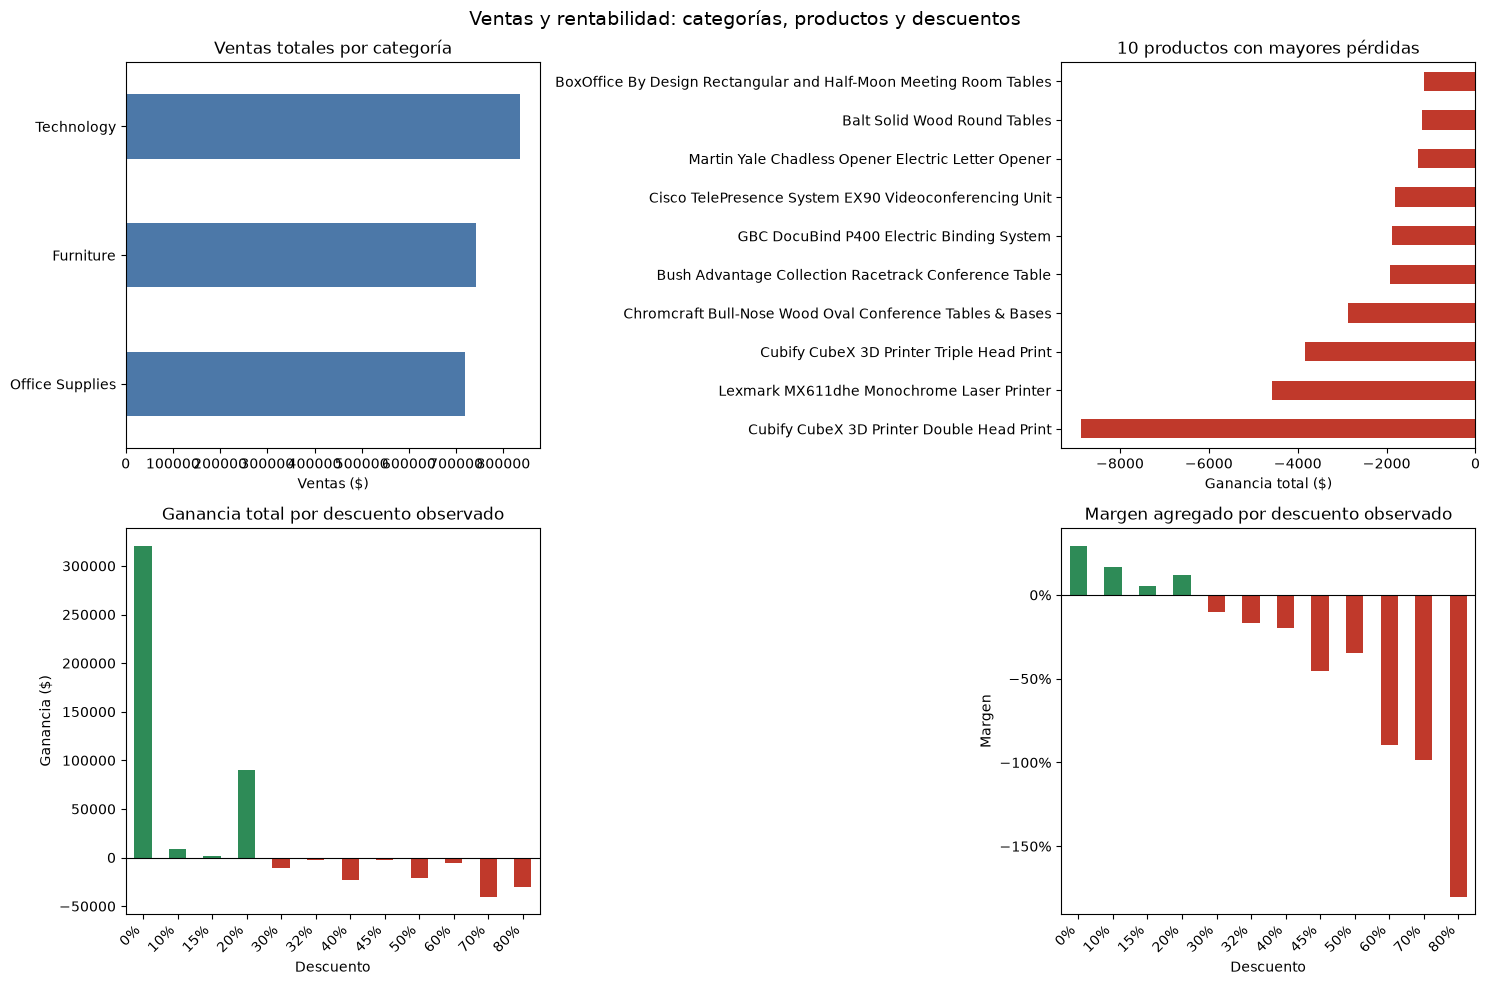

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sales_category.sort_values().plot(kind="barh", ax=axes[0, 0], color="#4C78A8")
axes[0, 0].set_title("Ventas totales por categoría")
axes[0, 0].set_xlabel("Ventas ($)")
axes[0, 0].set_ylabel("")

loss_products.sort_values("Profit").head(10)["Profit"].sort_values().plot(
    kind="barh", ax=axes[0, 1], color="#C0392B"
)
axes[0, 1].set_title("10 productos con mayores pérdidas")
axes[0, 1].set_xlabel("Ganancia total ($)")
axes[0, 1].set_ylabel("")

discount_colors = [
    "#2E8B57" if profit >= 0 else "#C0392B"
    for profit in discount_analysis["Profit"]
]
discount_labels = [f"{discount:.0%}" for discount in discount_analysis.index]
discount_analysis["Profit"].plot(
    kind="bar", ax=axes[1, 0], color=discount_colors, rot=45
)
axes[1, 0].set_title("Ganancia total por descuento observado")
axes[1, 0].set_xlabel("Descuento")
axes[1, 0].set_ylabel("Ganancia ($)")
axes[1, 0].set_xticklabels(discount_labels, ha="right")
axes[1, 0].axhline(0, color="black", linewidth=0.8)

discount_analysis["Profit Margin"].plot(
    kind="bar", ax=axes[1, 1], color=discount_colors, rot=45
)
axes[1, 1].set_title("Margen agregado por descuento observado")
axes[1, 1].set_xlabel("Descuento")
axes[1, 1].set_ylabel("Margen")
axes[1, 1].set_xticklabels(discount_labels, ha="right")
axes[1, 1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1, 1].axhline(0, color="black", linewidth=0.8)

fig.suptitle("Ventas y rentabilidad: categorías, productos y descuentos", fontsize=14)
fig.tight_layout()
plt.show()

## Análisis de rentabilidad por región y estado

In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   str           
 2   Order Date     9994 non-null   datetime64[us]
 3   Ship Date      9994 non-null   datetime64[us]
 4   Ship Mode      9994 non-null   str           
 5   Customer ID    9994 non-null   str           
 6   Customer Name  9994 non-null   str           
 7   Segment        9994 non-null   str           
 8   Country        9994 non-null   str           
 9   City           9994 non-null   str           
 10  State          9994 non-null   str           
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   str           
 13  Product ID     9994 non-null   str           
 14  Category       9994 non-null   str           
 15  Sub-Category   9994 non-null   s

In [19]:
# ¿Qué región genera más ventas?
sales_region = (df.groupby("Region")["Sales"].sum().sort_values(ascending=False))
print(sales_region)

Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050
Name: Sales, dtype: float64


In [20]:
# ¿Qué región genera mayor ganancia?
profit_region = (df.groupby("Region")["Profit"].sum().sort_values(ascending=False))
print(profit_region)

Region
West       108418.4489
East        91522.7800
South       46749.4303
Central     39706.3625
Name: Profit, dtype: float64


,Sales,Profit,Profit Margin
Region,,,
West,725457.8245,108418.4489,0.149448
East,678781.2400,91522.7800,0.134834
South,391721.9050,46749.4303,0.119343
Central,501239.8908,39706.3625,0.079216


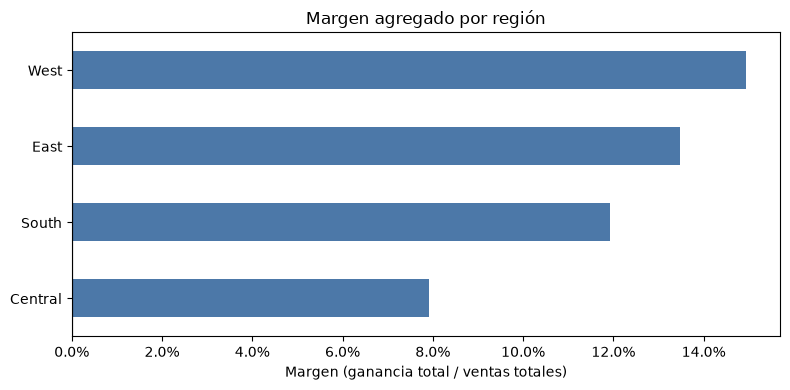

In [21]:
# ¿Qué región tiene mejor margen de rentabilidad?
region_analysis = df.groupby("Region").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
)
region_analysis["Profit Margin"] = region_analysis["Profit"] / region_analysis["Sales"]
region_analysis = region_analysis.sort_values("Profit Margin", ascending=False)
display(region_analysis)

region_analysis["Profit Margin"].sort_values().plot(
    kind="barh", figsize=(8, 4), color="#4C78A8",
    title="Margen agregado por región",
)
plt.xlabel("Margen (ganancia total / ventas totales)")
plt.ylabel("")
plt.gca().xaxis.set_major_formatter(PercentFormatter(1))
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

In [22]:
# ¿Qué estados aportan más utilidad total?
profit_state = (df.groupby("State")["Profit"].sum().sort_values(ascending=False))
print(profit_state)

State
California              76381.3871
New York                74038.5486
Washington              33402.6517
Michigan                24463.1876
Virginia                18597.9504
Indiana                 18382.9363
Georgia                 16250.0433
Kentucky                11199.6966
Minnesota               10823.1874
Delaware                 9977.3748
New Jersey               9772.9138
Wisconsin                8401.8004
Rhode Island             7285.6293
Maryland                 7031.1788
Massachusetts            6785.5016
Missouri                 6436.2105
Alabama                  5786.8253
Oklahoma                 4853.9560
Arkansas                 4008.6871
Connecticut              3511.4918
Nevada                   3316.7659
Mississippi              3172.9762
Utah                     2546.5335
Vermont                  2244.9783
Louisiana                2196.1023
Nebraska                 2037.0942
Montana                  1833.3285
South Carolina           1769.0566
New Hampshire 

In [23]:
# ¿Qué estados tienen pérdidas?
loss_state = (df.groupby("State").agg({"Sales":"sum",
       "Profit":"sum"}))

loss_state = loss_state.query("Profit < 0")
print(loss_state)

                      Sales      Profit
State                                  
Arizona          35282.0010  -3427.9246
Colorado         32108.1180  -6527.8579
Florida          89473.7080  -3399.3017
Illinois         80166.1010 -12607.8870
North Carolina   55603.1640  -7490.9122
Ohio             78258.1360 -16971.3766
Oregon           17431.1500  -1190.4705
Pennsylvania    116511.9140 -15559.9603
Tennessee        30661.8730  -5341.6936
Texas           170188.0458 -25729.3563


In [24]:
# Estados y valores de descuento con pérdidas (asociación descriptiva)
state_discount_analysis = (
    df.groupby(["State", "Discount"])
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Line_Items=("Row ID", "count"),
    )
)
state_discount_analysis["Profit Margin"] = (
    state_discount_analysis["Profit"] / state_discount_analysis["Sales"]
)
state_discount_losses = (
    state_discount_analysis.query("Profit < 0")
    .sort_values("Profit Margin")
    .head(15)
)
display(state_discount_losses)

,,Sales,Profit,Line_Items,Profit Margin
State,Discount,,,,
Texas,0.8,11450.490,-20852.2963,200,-1.821083
Illinois,0.8,5513.266,-9686.7429,100,-1.756988
Colorado,0.7,5406.180,-7172.6636,40,-1.326753
Oregon,0.7,847.626,-1089.4893,19,-1.285342
Ohio,0.7,10895.325,-13171.6128,81,-1.208923
Arizona,0.7,3670.515,-3446.8967,41,-0.939077
Illinois,0.6,2877.976,-2631.9766,57,-0.914523
Texas,0.6,3766.724,-3312.6786,81,-0.879459
Pennsylvania,0.7,8399.775,-6790.2206,105,-0.808381


In [25]:
df.describe()

,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit,year,month
count,9994.000000,9994,9994,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,2016-04-30 00:07:12.259355,2016-05-03 23:06:58.571142,55190.379428,229.858001,3.789574,0.156203,28.656896,2015.722233,7.809686
min,1.000000,2014-01-03 00:00:00,2014-01-07 00:00:00,1040.000000,0.444000,1.000000,0.000000,-6599.978000,2014.000000,1.000000
25%,2499.250000,2015-05-23 00:00:00,2015-05-27 00:00:00,23223.000000,17.280000,2.000000,0.000000,1.728750,2015.000000,5.000000
50%,4997.500000,2016-06-26 00:00:00,2016-06-29 00:00:00,56430.500000,54.490000,3.000000,0.200000,8.666500,2016.000000,9.000000
75%,7495.750000,2017-05-14 00:00:00,2017-05-18 00:00:00,90008.000000,209.940000,5.000000,0.200000,29.364000,2017.000000,11.000000
max,9994.000000,2017-12-30 00:00:00,2018-01-05 00:00:00,99301.000000,22638.480000,14.000000,0.800000,8399.976000,2017.000000,12.000000
std,2885.163629,NaN,NaN,32063.693350,623.245101,2.225110,0.206452,234.260108,1.123555,3.284654


## Conclusiones y recomendaciones

### Hallazgos

- En las 9.994 líneas analizadas, las ventas suman **$2.297.200,86** y la ganancia **$286.397,02**, con un margen agregado de **12,47%**.
- Las tres categorías son rentables. **Technology** aporta la mayor ganancia (**$145.454,95; margen 17,40%**), seguida de **Office Supplies** (**$122.490,80; 17,04%**). **Furniture** aporta solo **$18.451,27** y tiene el margen más bajo (**2,49%**).
- Las pérdidas por subcategoría se concentran en **Tables** (**-$17.725,48**), **Bookcases** (**-$3.472,56**) y **Supplies** (**-$1.189,10**). A nivel producto, **301 de 1.850** productos presentan ganancia total negativa; las mayores pérdidas corresponden a **Cubify CubeX 3D Printer Double Head Print** (**-$8.879,97**), **Lexmark MX611dhe Monochrome Laser Printer** (**-$4.589,97**) y **Cubify CubeX 3D Printer Triple Head Print** (**-$3.839,99**).
- Todas las regiones son rentables, pero **Central** tiene el menor margen (**7,92%**) frente a **West** (**14,94%**), la región con mayor ganancia total y margen. Por estado, **Texas** registra la mayor pérdida (**-$25.729,36**), seguido de **Ohio** (**-$16.971,38**) y **Pennsylvania** (**-$15.559,96**).
- Los descuentos observados de **30% a 80%** presentan ganancia agregada negativa en este dataset; los valores de 0% a 20% son positivos. El margen agregado va de **-10,05%** con 30% de descuento a **-180,03%** con 80%. Algunos descuentos tienen pocas líneas (por ejemplo, 45% tiene 11), por lo que esos resultados requieren cautela.

### Recomendaciones

1. Revisar primero precios, costos y descuentos de **Tables**, **Bookcases** y **Supplies**, y de los productos con mayores pérdidas; priorizar los que combinan pérdidas grandes con ventas relevantes.
2. Auditar la política de descuentos de **30% o más** por subcategoría y estado. Antes de limitar descuentos, comparar productos y condiciones equivalentes para separar el efecto del mix de productos y otros costos; estos datos muestran asociación, no causalidad.
3. Investigar la baja rentabilidad de **Central** y las pérdidas de **Texas**, **Ohio** y **Pennsylvania** con un desglose adicional de categoría, producto y descuento. Usar **West** como referencia de desempeño, no como prueba de que sus prácticas sean transferibles.

Los resultados son descriptivos para este dataset y periodo (**2014–2017**); no deben interpretarse como estimaciones causales ni como garantía de desempeño futuro.